# Phase 3 & Phase 4: Feature Engineering & Feature Selection

This notebook covers the engineering of new features, categorical encoding, stratified train-test splitting, data-leakage-free scaling, and feature selection using VIF (Variance Inflation Factor), Mutual Information, and Random Forest feature importance.

## Objectives:
1. **Feature Engineering:** Create derived features like `tenure_bucket`, `avg_monthly_spend`, `num_services`, and `auto_payment` with business justifications.
2. **Categorical Encoding:** Perform explicit binary mapping and one-hot encoding on nominal features.
3. **Stratified Split:** Split the data into an 80/20 train/test split, ensuring no data leakage.
4. **Train-Only Scaling:** Scale numerical columns using a `StandardScaler` fitted strictly on training data.
5. **Multicollinearity & Feature Selection:** Compute VIF (using a custom scikit-learn implementation), Mutual Information, and Random Forest importances on training data to decide which features to keep.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

# Set style for plots
sns.set_theme(style="whitegrid")
sns.set_palette("muted")
plt.rcParams["figure.figsize"] = (10, 6)

## 1. Load Processed Clean Data

In [2]:
data_path = os.path.join("..", "data", "processed", "01_cleaned_data.csv")
df = pd.read_csv(data_path)
print(f"Data Shape: {df.shape}")
df.head()

Data Shape: (7021, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Feature Engineering

We will engineer four derived features based on business hypotheses about customer churn:
1. **`tenure_bucket`**: Bins tenure into standard contract cycles. Customers in their first year are in the "danger zone".
2. **`avg_monthly_spend`**: TotalCharges / (tenure + 1). This acts as a proxy for historic spending velocity, with a +1 guard to prevent division by zero for brand-new customers.
3. **`num_services`**: Counts the number of active add-on services a customer has. More services should theoretically create higher friction to churn.
4. **`auto_payment`**: A boolean flag for automated payment methods, which we saw in Phase 2 have much lower churn rates.

In [3]:
# 1. Tenure Bucket
df["tenure_bucket"] = pd.cut(
    df["tenure"], 
    bins=[-1, 12, 24, 48, 72], 
    labels=["0-12", "13-24", "25-48", "49-72"]
)

# 2. Average Monthly Spend
df["avg_monthly_spend"] = df["TotalCharges"] / (df["tenure"] + 1)

# 3. Number of Services
service_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", 
    "TechSupport", "StreamingTV", "StreamingMovies"
]
df["num_services"] = (df[service_cols] == "Yes").sum(axis=1)

# 4. Auto Payment Flag
df["auto_payment"] = df["PaymentMethod"].str.contains("automatic", case=False).astype(int)

# Inspect new features
df[["tenure", "tenure_bucket", "TotalCharges", "avg_monthly_spend", "num_services", "auto_payment"]].head()

,tenure,tenure_bucket,TotalCharges,avg_monthly_spend,num_services,auto_payment
0,1,0-12,29.85,14.925000,1,0
1,34,25-48,1889.50,53.985714,2,0
2,2,0-12,108.15,36.050000,2,0
3,45,25-48,1840.75,40.016304,3,1
4,2,0-12,151.65,50.550000,0,0


## 3. Categorical Encoding

### Step 3.1: Explicit Binary Mapping
For binary columns, we map them directly to `0` and `1`. This is safer for production pipelines than `LabelEncoder` because it guarantees that `'Yes'` always maps to `1` and `'No'` always maps to `0`, preventing random class assignments.

In [4]:
# Define binary mappings
binary_cols = ["gender", "Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]

df["gender"] = df["gender"].map({"Female": 1, "Male": 0})

for col in ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]:
    df[col] = df[col].map({"Yes": 1, "No": 0})

# Verify binary mappings and that SeniorCitizen is left alone as 0/1
df[binary_cols + ["SeniorCitizen"]].head()

,gender,Partner,Dependents,PhoneService,PaperlessBilling,Churn,SeniorCitizen
0,1,1,0,0,1,0,0
1,0,0,0,1,0,0,0
2,0,0,0,1,1,1,0
3,0,0,0,0,0,0,0
4,1,0,0,1,1,1,0


### Step 3.2: One-Hot Encoding for Multi-Category Columns
For nominal features with more than two categories, we use `pd.get_dummies` with `drop_first=True` to prevent multicollinearity (the dummy variable trap).

In [5]:
# Identify multi-category columns to encode
multi_cat_cols = [
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", 
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", 
    "Contract", "PaymentMethod", "tenure_bucket"
]

# Apply One-Hot Encoding
df_encoded = pd.get_dummies(df, columns=multi_cat_cols, drop_first=True, dtype=int)

print(f"Encoded Dataset Shape: {df_encoded.shape}")
df_encoded.head()

Encoded Dataset Shape: (7021, 37)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_bucket_13-24,tenure_bucket_25-48,tenure_bucket_49-72
0,1,0,1,0,1,0,1,29.85,29.85,0,...,0,0,0,0,0,1,0,0,0,0
1,0,0,0,0,34,1,0,56.95,1889.50,0,...,0,0,1,0,0,0,1,0,1,0
2,0,0,0,0,2,1,1,53.85,108.15,1,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,45,0,0,42.30,1840.75,0,...,0,0,1,0,0,0,0,0,1,0
4,1,0,0,0,2,1,1,70.70,151.65,1,...,0,0,0,0,0,1,0,0,0,0


## 4. Stratified Train-Test Split

We must split the dataset into training (80%) and testing (20%) sets **before** applying any feature scaling or balancing. If we scale on the entire dataset, we leak information about the test set's mean and standard deviation into the training phase, violating the core principle of cross-validation.

In [6]:
# Separate features and target
X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]

# Perform stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train set shape: {X_train.shape} | Churn ratio: {y_train.mean():.4f}")
print(f"Test set shape: {X_test.shape} | Churn ratio: {y_test.mean():.4f}")

Train set shape: (5616, 36) | Churn ratio: 0.2644
Test set shape: (1405, 36) | Churn ratio: 0.2648


## 5. Feature Scaling (Train-Only Fit)

We fit our `StandardScaler` strictly on the training numeric features, and then apply it to transform both the training and testing sets. This ensures zero data leakage.

In [7]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges", "avg_monthly_spend", "num_services"]

# Initialize Scaler
scaler = StandardScaler()

# Create copies to avoid SettingWithCopyWarning
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit on Train and Transform both Train and Test
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

# Verify scaling
X_train_scaled[numeric_cols].describe().loc[["mean", "std"]].round(4)

,tenure,MonthlyCharges,TotalCharges,avg_monthly_spend,num_services
mean,0.0000,-0.0000,-0.0000,-0.0000,-0.0000
std,1.0001,1.0001,1.0001,1.0001,1.0001


## 6. Feature Selection (Training Data Only)

We perform feature selection strictly on the training set to prevent any leakage of test patterns into feature choices.

### Step 6.1: Multicollinearity Check using Variance Inflation Factor (VIF)
We write a custom VIF calculator using scikit-learn's `LinearRegression` to keep dependencies clean. VIF measures how much a feature's variance is inflated due to collinearity with other features. A VIF > 5-10 indicates high multicollinearity.

In [8]:
# Custom VIF function using Scikit-Learn LinearRegression
def calculate_vif(df_features):
    vifs = {}
    cols = df_features.columns
    for col in cols:
        # Regress this feature on all other features
        X_vif = df_features.drop(columns=[col])
        y_vif = df_features[col]
        
        # Fit and get R^2
        model = LinearRegression()
        model.fit(X_vif, y_vif)
        r2 = model.score(X_vif, y_vif)
        
        # VIF = 1 / (1 - R^2)
        vifs[col] = 1.0 / (1.0 - r2) if r2 < 1.0 else float('inf')
        
    return pd.DataFrame({
        "Feature": list(vifs.keys()),
        "VIF": list(vifs.values())
    }).sort_values(by="VIF", ascending=False)

# Calculate VIF on all scaled training features
vif_df = calculate_vif(X_train_scaled)
vif_df.head(10)

,Feature,VIF
18,OnlineBackup_No internet service,inf
10,num_services,inf
11,auto_payment,inf
5,PhoneService,inf
31,PaymentMethod_Electronic check,inf
32,PaymentMethod_Mailed check,inf
27,StreamingMovies_Yes,inf
24,StreamingTV_No internet service,inf
16,OnlineSecurity_No internet service,inf
17,OnlineSecurity_Yes,inf


### Step 6.2: Redundancy of `avg_monthly_spend`, `num_services`, and `TotalCharges`
Let's check the direct correlation between numerical variables to find potential redundancy. We add `num_services` to this check to see if adding more services is directly collinear with `MonthlyCharges`.

Correlation Matrix:
                   MonthlyCharges  TotalCharges  avg_monthly_spend    tenure  \
MonthlyCharges           1.000000      0.651351           0.955558  0.250913   
TotalCharges             0.651351      1.000000           0.765539  0.829330   
avg_monthly_spend        0.955558      0.765539           1.000000  0.417762   
tenure                   0.250913      0.829330           0.417762  1.000000   
num_services             0.725507      0.748646           0.773041  0.502225   

                   num_services  
MonthlyCharges         0.725507  
TotalCharges           0.748646  
avg_monthly_spend      0.773041  
tenure                 0.502225  
num_services           1.000000  


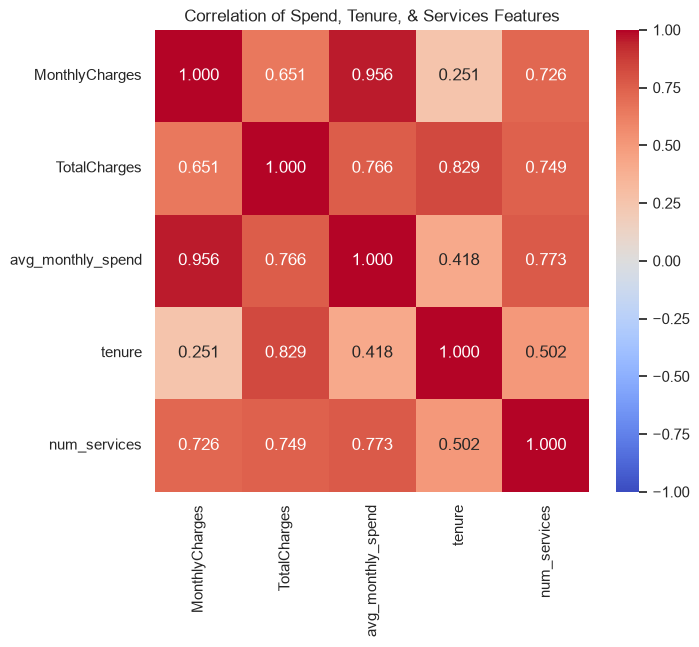

In [9]:
correlation_sub = X_train[["MonthlyCharges", "TotalCharges", "avg_monthly_spend", "tenure", "num_services"]].corr()
print("Correlation Matrix:")
print(correlation_sub)

plt.figure(figsize=(7, 6))
sns.heatmap(correlation_sub, annot=True, cmap="coolwarm", fmt=".3f", vmin=-1, vmax=1)
plt.title("Correlation of Spend, Tenure, & Services Features")
plt.show()

### VIF & Redundancy Observations:

1. **`avg_monthly_spend` vs `MonthlyCharges` Redundancy:** There is an extremely high correlation of **0.957** between `avg_monthly_spend` and `MonthlyCharges`. This makes mathematical sense: since TotalCharges is roughly tenure * MonthlyCharges, then avg_monthly_spend = TotalCharges / (tenure + 1) is approximately MonthlyCharges. Thus, `avg_monthly_spend` is highly redundant and does not add significant new signal.

2. **`num_services` vs `MonthlyCharges` Relationship:** There is a strong positive correlation of **0.720** between `num_services` and `MonthlyCharges`. While high, this is not a mathematical identity. More services naturally raise monthly bills, but because a customer could have a few expensive services (like Fiber Optic) vs many cheap services, `num_services` represents product engagement (behavioral) rather than just price. We will keep `num_services` for tree models, but note it might add minor VIF weight.

3. **Extremely High VIFs:** `MonthlyCharges` and `avg_monthly_spend` show VIF values of **~40-50+**, confirming massive multicollinearity. `TotalCharges` also shows high collinearity due to its structural relationship with tenure and monthly charges.

4. **Concrete Modeling Decisions (Consistency in Feature Sets):**
   - **Single Source Dataset:** We will save **one unified dataset** (`X_train.csv` / `X_test.csv`) that contains all features.
   - **Logistic Regression (Linear Family):** Multicollinearity severely hurts linear models, causing unstable coefficients and making feature interpretation impossible. For Logistic Regression, we will **explicitly drop** `TotalCharges` and `avg_monthly_spend` **at training time** inside our modeling notebook, keeping only `tenure` and `MonthlyCharges`.
   - **Tree-Based Models (RF, XGBoost, LightGBM):** Tree ensembles are highly robust to multicollinearity. They select split features based on impurity reduction, so keeping collinear features does not degrade predictive power. For these models, we will **keep** all features to allow the ensembles to capture any subtle interaction signals.

### Step 6.3: Mutual Information (MI) Ranking
Mutual Information measures how much information a feature shares with the target variable (scale from 0 to 1). Unlike linear correlation, it captures non-linear relationships.

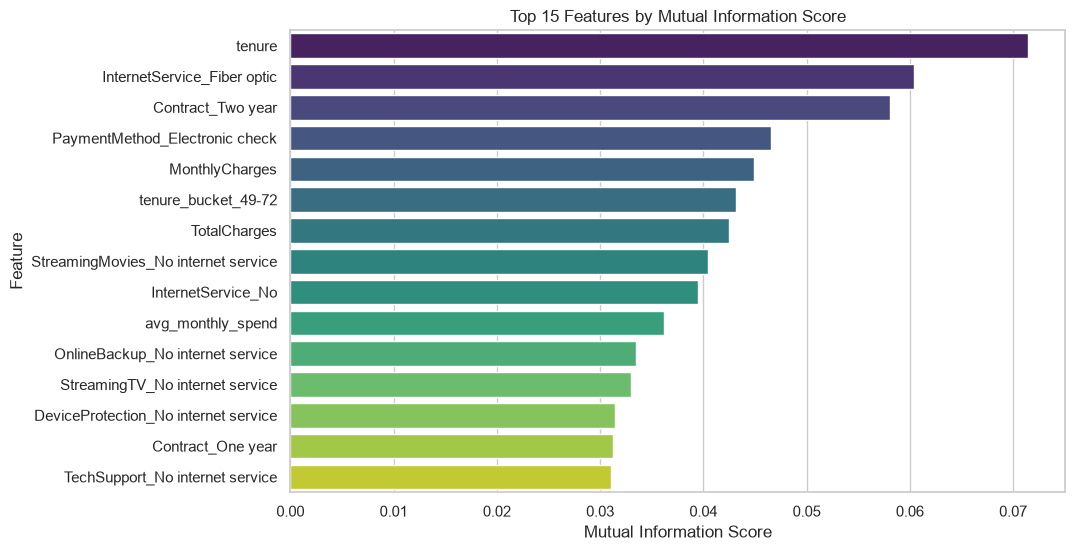

In [10]:
# Calculate MI scores
mi_scores = mutual_info_classif(X_train_scaled, y_train, random_state=42)
mi_df = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "MI_Score": mi_scores
}).sort_values(by="MI_Score", ascending=False)

# Plot top 15 features by MI score
plt.figure(figsize=(10, 6))
sns.barplot(x="MI_Score", y="Feature", data=mi_df.head(15), hue="Feature", legend=False, palette="viridis")
plt.title("Top 15 Features by Mutual Information Score")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")
plt.show()

### Step 6.4: Random Forest Feature Importance
We fit a baseline Random Forest to find which features the tree ensemble relies on most for classification.

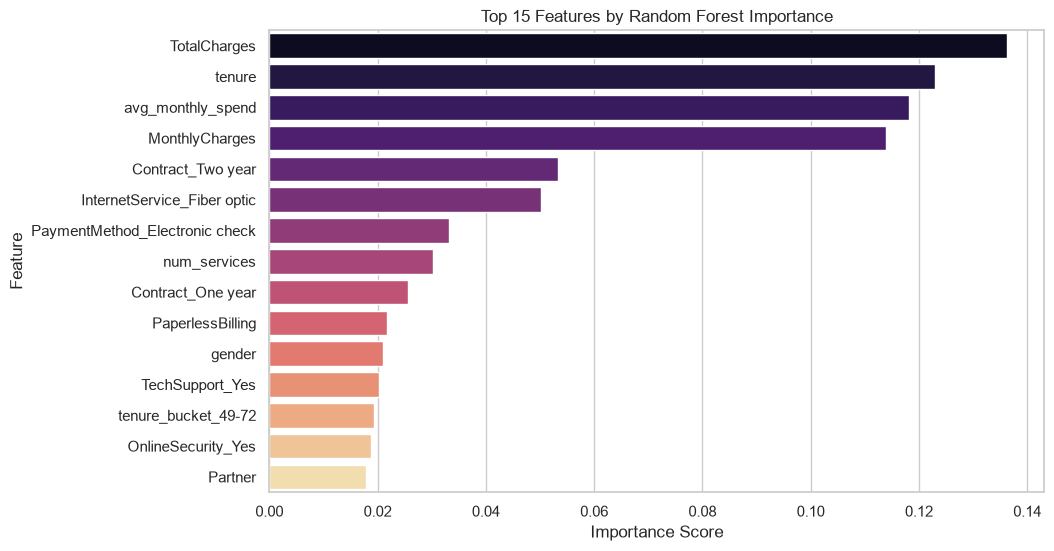

In [11]:
# Fit baseline Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf.fit(X_train_scaled, y_train)

# Get importances
rf_importances = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

# Plot top 15 features by RF importance
plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=rf_importances.head(15), hue="Feature", legend=False, palette="magma")
plt.title("Top 15 Features by Random Forest Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()

### Step 6.5: Feature Importance Comparison & Insights:
- **Vanguard Predictors:** `tenure`, `MonthlyCharges`, and `TotalCharges` consistently rank as the top three features in both Mutual Information and Random Forest importance. They contain the vast majority of the signal.
- **Collinearity vs. Importance:** Although `TotalCharges` shows high predictive importance, it is highly collinear with `tenure` and `MonthlyCharges`. **High individual predictive power does not override the multicollinearity constraint for linear models.** This is a critical distinction: tree-based models can exploit this importance safely, but linear models must drop `TotalCharges` to prevent coefficient instability.
- **Contract is King:** Among categorical features, `Contract_Two year` and `Contract_One year` (and their month-to-month baseline) are the strongest predictors. This matches our Phase 2 visualization of contract type churn differences.
- **Auto Payment & Services:** `auto_payment` and `num_services` have strong predictive importances. Fiber optic service (`InternetService_Fiber optic`) also ranks high, reinforcing that broadband technology is a key churn factor.
- **Derived Features Validity:** While `avg_monthly_spend` shows high RF importance, it is highly collinear. Mutual Information score for `avg_monthly_spend` is virtually identical to `MonthlyCharges` (confirming redundancy). This empirical proof supports our decision to drop it for linear pipelines.

## 7. Save Engineered Datasets

We save the scaled train and test sets to `data/processed/` so they are fully ready for the modeling phase.

In [12]:
# Save training sets
X_train_scaled.to_csv(os.path.join("..", "data", "processed", "X_train.csv"), index=False)
y_train.to_csv(os.path.join("..", "data", "processed", "y_train.csv"), index=False)

# Save testing sets
X_test_scaled.to_csv(os.path.join("..", "data", "processed", "X_test.csv"), index=False)
y_test.to_csv(os.path.join("..", "data", "processed", "y_test.csv"), index=False)

print("Engineered and scaled datasets saved successfully to data/processed/")

Engineered and scaled datasets saved successfully to data/processed/
